**Task 1**

In [2]:
import os
import hashlib
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt
import random
import seaborn as sns


def get_filehash(file_path):
    sha256_hash=hashlib.sha256()
    with open(file_path, "rb") as f:
        for byte_block in iter(lambda: f.read(8192), b""):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

def audit_dataset(dataset_dirs):
    metadata_list = []
    corrupt_files = []
    for class_name, folder_path in dataset_dirs.items():
        for root, dirs, files in os.walk(folder_path):
            for file in files:
                file_path = os.path.join(root, file)
        
                try:
                    with Image.open(file_path) as img:
                        width, height = img.size
                        color_mode = img.mode
                        img_format = img.format
                        file_size = os.path.getsize(file_path)
                        file_hash = get_filehash(file_path)

                        metadata_list.append({
                            "class": class_name,
                            "file_name": file,
                            "file_path": file_path,
                            "file_size_bytes": file_size,
                            "width": width,
                            "height": height,
                            "color_mode": color_mode,
                            "format": img_format,
                            "sha256": file_hash
                        })
                
                except Exception as e:
                    corrupt_files.append({
                        "file_path": file_path,
                        "error": str(e)
                    })

    return metadata_list, corrupt_files

def plot_ai_sample_images(df, num_samples=5):
  class_df = df[df["class"] == "AIGenerated"]
  sample_paths = class_df["file_path"].sample(
      n=min(num_samples, len(class_df)), random_state=42
  ).tolist()

  fig, axes = plt.subplots(1, num_samples, figsize=(15, 3), squeeze=False)
  for col_idx, path in enumerate(sample_paths):
    ax = axes[0, col_idx]
    try:
      img = Image.open(path)
      ax.imshow(img)
      ax.axis("off")
    except Exception:
      ax.text(
          0.5,
          0.5,
          "Error loading",
          ha="center",
          va="center",
          transform=ax.transAxes,
      )
      ax.axis("off")

  plt.suptitle(
      "Figure 1: Sample AI-Generated Images", fontsize=14, fontweight="bold"
  )
  plt.tight_layout()
  plt.savefig("ai_sample_images.png")
  plt.show()


def plot_real_sample_images(df, num_samples=5):
  class_df = df[df["class"] == "Real"]
  sample_paths = class_df["file_path"].sample(
      n=min(num_samples, len(class_df)), random_state=42
  ).tolist()

  fig, axes = plt.subplots(1, num_samples, figsize=(15, 3), squeeze=False)
  for col_idx, path in enumerate(sample_paths):
    ax = axes[0, col_idx]
    try:
      img = Image.open(path)
      ax.imshow(img)
      ax.axis("off")
    except Exception:
      ax.text(
          0.5,
          0.5,
          "Error loading",
          ha="center",
          va="center",
          transform=ax.transAxes,
      )
      ax.axis("off")

  plt.suptitle("Figure 2: Sample Real Images", fontsize=14, fontweight="bold")
  plt.tight_layout()
  plt.savefig("real_sample_images.png")
  plt.show()



def plot_feature_histograms(df):
  fig, axes = plt.subplots(1, 3, figsize=(18, 5))

  features = ["width", "height", "file_size_bytes"]
  titles = [
      "Image Width Distribution",
      "Image Height Distribution",
      "File Size Distribution (Bytes)",
  ]

  for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        hue="class",
        element="step",
        common_norm=False,
        stat="density",
        ax=axes[i],
        palette="tab10",
        alpha=0.4,
    )
    axes[i].set_title(titles[i], fontsize=11, fontweight="bold")
    axes[i].set_xlabel(feature.capitalize())
    axes[i].set_ylabel("Density")

  plt.suptitle(
      "Figure 2: Comparative Distributions of Image Dimensions and File Sizes",
      fontsize=14,
      fontweight="bold",
  )
  plt.tight_layout()
  plt.savefig("feature_histograms.png")
  plt.show()

class
AIGenerated    539
Real           436
Name: count, dtype: int64
WIDTH -> Min: 183, Median: 1024.0, Max: 8495
HEIGHT -> Min: 135, Median: 768.0, Max: 7091
FILE_SIZE_BYTES -> Min: 11311, Median: 169093.0, Max: 10195352

Total Corrupt Files: 0
Total Duplicate Files Found: 2
Rows before cleaning: 975, after: 974


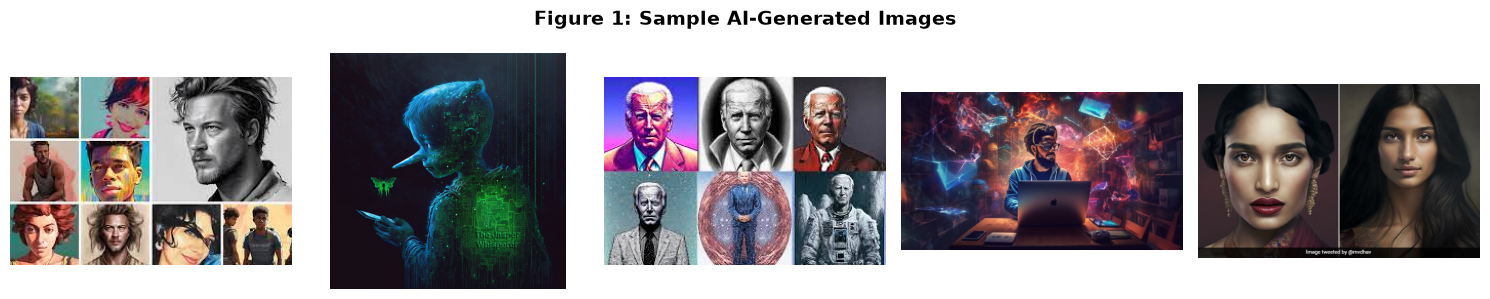

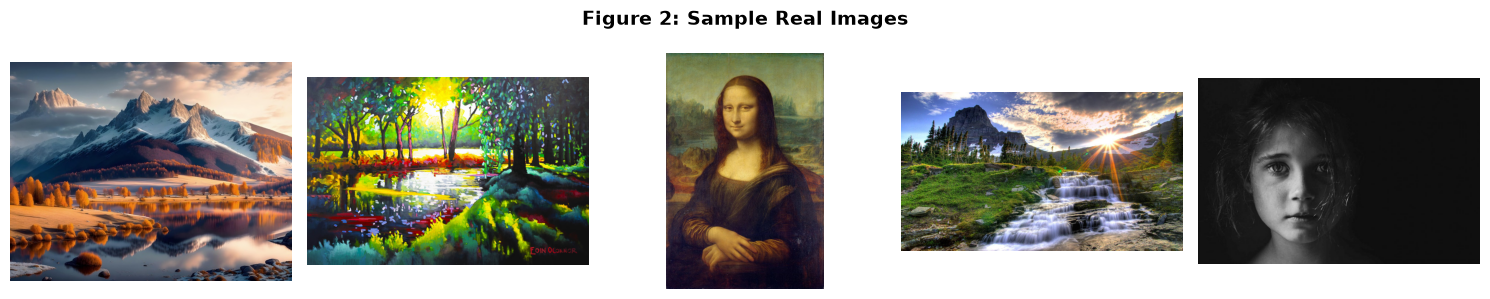

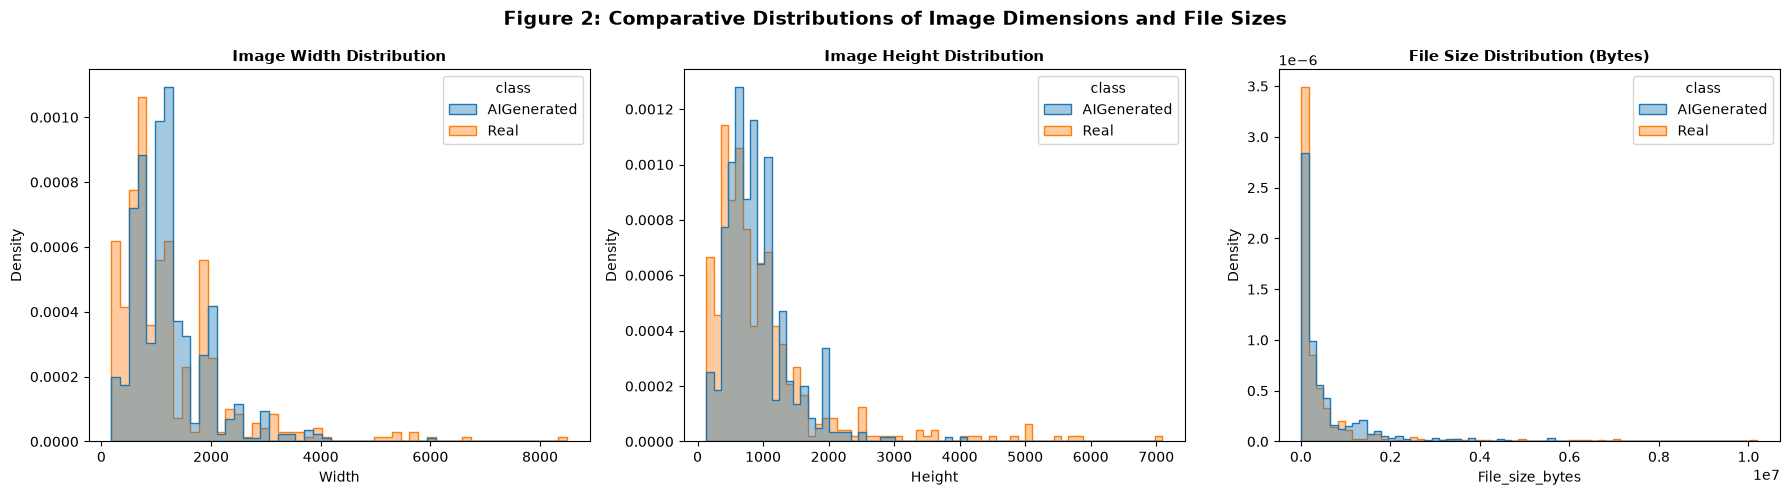

In [3]:
import os
import hashlib
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

DATASET_DIRS = {
    "AIGenerated": "Data/AiArtData",
    "Real": "Data/RealArt"
}


data_list, corrupt_list=audit_dataset(DATASET_DIRS)
df=pd.DataFrame(data_list)
print(df['class'].value_counts())

for col in ['width', 'height', 'file_size_bytes']:
    print(f"{col.upper()} -> Min: {df[col].min()}, Median: {df[col].median()}, Max: {df[col].max()}")

print(f"\nTotal Corrupt Files: {len(corrupt_list)}")
duplicates_df = df[df.duplicated(subset=['sha256'], keep=False)]
print(f"Total Duplicate Files Found: {len(duplicates_df)}")

conflict = df.groupby("sha256")["class"].nunique()
conflict_hashes = conflict[conflict > 1].index
df_clean = df[~df["sha256"].isin(conflict_hashes)].drop_duplicates(subset=["sha256"], keep="first")
print(f"Rows before cleaning: {len(df)}, after: {len(df_clean)}")


plot_ai_sample_images(df_clean)
plot_real_sample_images(df_clean)
plot_feature_histograms(df_clean)

**Task 2**

In [4]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

def load_and_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

def augment(image, label):                                  # random changes, applied to training images only
    image = tf.image.random_flip_left_right(image)          # 50% chance to mirror the image left to right
    image = tf.image.random_brightness(image, max_delta=25.0)  # add a random brightness shift of up to ±25 (0-255 scale)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)  # multiply contrast by a random factor between 0.9 and 1.1
    image = tf.clip_by_value(image, 0.0, 255.0)             # force every pixel back into the valid 0-255 range
    return image, label                                     # pass the changed image and its unchanged label on

def make_dataset(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))   # one (path, label) item per image
    if training:
        ds = ds.shuffle(buffer_size=1000, seed=42, reshuffle_each_iteration=True)  # shuffle within a 1000-item window
    ds = ds.map(load_and_resize, num_parallel_calls=4)        # read and resize with 4 workers, not unlimited
    if training:
        ds = ds.map(augment, num_parallel_calls=4)            # augment with 4 workers
    ds = ds.batch(BATCH_SIZE)                                 # group into batches of 32
    ds = ds.prefetch(2)                                       # keep at most 2 batches ready ahead of time
    return ds

2026-10-26 02:50:05.859524: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
from sklearn.model_selection import train_test_split

paths = df_clean["file_path"].tolist()          
labels = df_clean["class"].map({"Real": 0, "AIGenerated": 1}).tolist()


train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42,
)


val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42,
)

print("Train:", len(train_paths), "Val:", len(val_paths), "Test:", len(test_paths))
print("Train class counts:", train_labels.count(0), "Real,", train_labels.count(1), "AI")

Train: 681 Val: 146 Test: 147
Train class counts: 305 Real, 376 AI


I0000 00:00:1792983010.655951    2988 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12519 MB memory:  -> device: 0, name: AMD Radeon RX 9060 XT, pci bus id: 0000:03:00.0
2026-10-26 02:50:12.718857: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 11059200 exceeds 10% of free system memory.
2026-10-26 02:50:12.768074: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 7291200 exceeds 10% of free system memory.
2026-10-26 02:50:12.801968: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 57802752 exceeds 10% of free system memory.
2026-10-26 02:50:12.900408: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 23970816 exceeds 10% of free system memory.
2026-10-26 02:50:12.935308: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 13109760 exceeds 10% of free system memory.
2026-10-26 02:50:13.016453: W tensorf

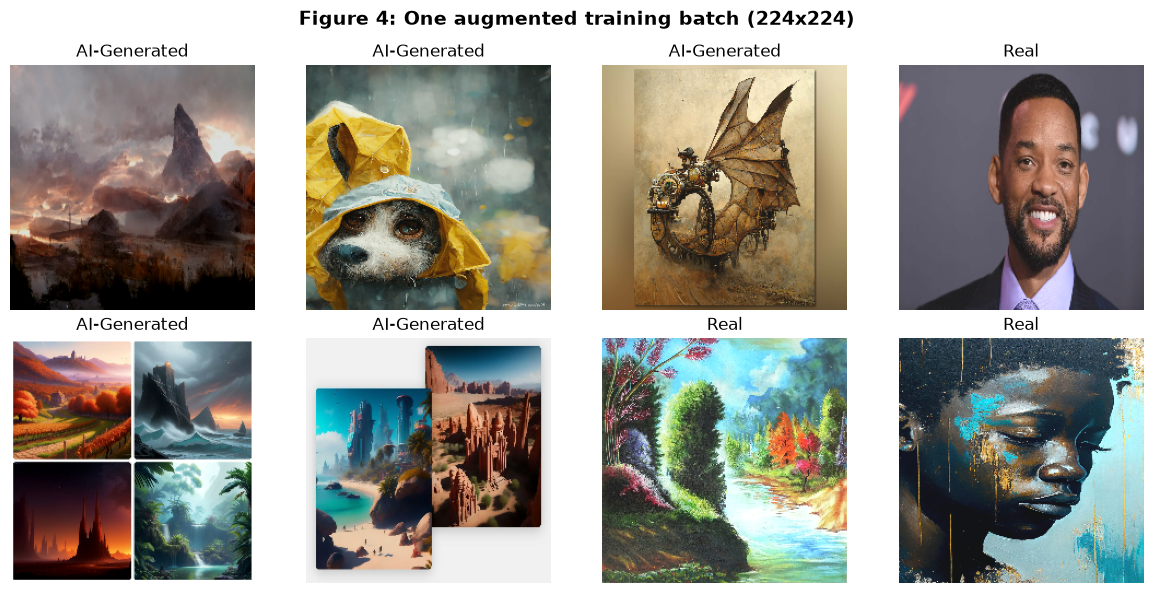

2026-10-26 02:50:13.798834: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [6]:
import matplotlib.pyplot as plt

class_names = {0: "Real", 1: "AI-Generated"}

train_ds = make_dataset(train_paths, train_labels, training=True)

for images, labels in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i, ax in enumerate(axes.flat):
        img = images[i].numpy().astype("uint8")
        ax.imshow(img)
        ax.set_title(class_names[int(labels[i])])
        ax.axis("off")

    fig.suptitle("Figure 4: One augmented training batch (224x224)",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("augmented_batch.png", dpi=150)
    plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_baseline_cnn(input_shape=(128, 128, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        
        layers.Dense(1, activation='sigmoid')
    ], name="VisionGuard_Baseline_CNN")
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[
            'accuracy', 
            tf.keras.metrics.Precision(name='precision'), 
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    
    return model

model = build_baseline_cnn()
model.summary()

I0000 00:00:1793521821.590986   19958 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793521822.198346   19958 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793521823.869327   19958 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793521827.251135   19958 gpu_device.cc:2042] Created device /job:localhost/

Model: "VisionGuard_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,217 (16.36 MB)

 Trainable params: 4,288,513 (16.36 MB)

 Non-trainable params: 704 (2.75 KB)